# Measuring Roman SN magnification

A standardized Type Ia supernova brightness can measure **flux magnification**. In this notebook we read a simulated Roman response, inspect how selection changes the brightness distribution, and evaluate the likelihood for one training event.

You will need basic NumPy and magnitude notation. Run the cells in order with the dependencies in the repository's `requirements_notebooks.txt` and its Python kernel. No package installation is needed to import the local source.

1. Connect magnification to flux and magnitude.
2. Inspect the bundled Roman response.
3. Read a brightness likelihood and try changing the residual.

The Roman calibration and event below are simulated. The opening light curve is a labeled schematic, not Roman photometry.

In [1]:
from pathlib import Path
import sys

repo = Path.cwd()
if not (repo / "ilsn").is_dir():
    repo = repo.parent
if not (repo / "data" / "roman_response.npz").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(repo))

import numpy as np
import matplotlib.pyplot as plt
from ilsn.supernova import magnification_to_shift
from ilsn.response import ResponseCalibration
from ilsn.likelihood import magnification_log_likelihood

%matplotlib inline

blue, orange = "#2b5b8e", "#c77932"
plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "dejavuserif", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 110,
})

## From flux to a magnitude shift

For a positive flux magnification $\mu$, lensing scales flux by $F_{\rm lensed}=\mu F_0$. In the absence of attenuation, the photon magnitude shift is

$$d=-2.5\log_{10}\mu.$$

A brighter source has $\mu>1$ and $d<0$. The schematic below illustrates a constant flux scaling for a single light curve; it omits time delays, dust and microlensing.

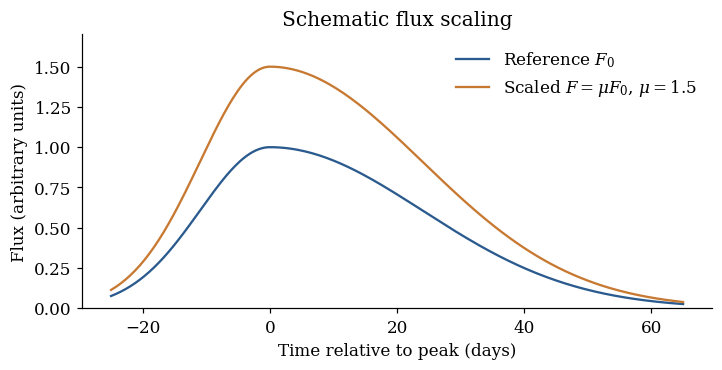

A flux factor 1.5 gives d = -0.440 mag.


In [2]:
time_days = np.linspace(-25, 65, 240)
# An arbitrary asymmetric pulse; no SN template or observed flux is used here.
width_days = np.where(time_days < 0, 11.0, 24.0)
flux_shape = np.exp(-0.5 * (time_days / width_days)**2)
schematic_mu = 1.5

fig, ax = plt.subplots(figsize=(6.7, 3.5))
ax.plot(time_days, flux_shape, color=blue, label=r"Reference $F_0$")
ax.plot(time_days, schematic_mu * flux_shape, color=orange,
        label=rf"Scaled $F=\mu F_0$, $\mu={schematic_mu:.1f}$")
ax.set(xlabel="Time relative to peak (days)", ylabel="Flux (arbitrary units)",
       title="Schematic flux scaling", ylim=(0, 1.7))
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
print(f"A flux factor {schematic_mu:.1f} gives d = {magnification_to_shift(schematic_mu):.3f} mag.")

## Read the simulated Roman response

`roman_response.npz` contains the **TRAIN20** calibration from simulated Type Ia SNe processed with SNANA/PIPPIN. At each of six true-redshift centers, 600 matched parents were simulated at zero shift and across the 20-knot photon-shift grid.

The observable is $y=R-C_0$: a fixed raw Tripp residual relative to a prescribed distance law, centered with one fixed control origin. It is not a BBC-corrected `MURES` value. See [the data description](../data/README.rst) for the standardization coefficients, reference distance and quality selection.

In [3]:
response = ResponseCalibration.load(repo / "data" / "roman_response.npz")
true_redshift = 1.2
redshift_nodes = response.metadata["redshift_conditioning"]["nodes"]
print("Calibrated true redshifts:", ", ".join(str(z) for z in redshift_nodes))
print(f"Photon-shift support: [{response.shift_nodes[0]:.2f}, {response.shift_nodes[-1]:.2f}] mag")
print(f"Knots: {len(response.shift_nodes)}; joint calibration draws: {response.n_draws}")
print(f"Fixed control origin C0 = {response.control_scalar:.5f} mag")

Calibrated true redshifts: 0.55, 0.6, 0.85, 1.2, 1.7, 2.475
Photon-shift support: [-3.20, 0.50] mag
Knots: 20; joint calibration draws: 2000
Fixed control origin C0 = -19.35849 mag


## Mean, variance and delivery

The response provides three functions of photon shift $d$ and true redshift $z$:

- $m(d,z)$: mean residual among delivered SNe, in mag.
- $v(d,z)$: variance among delivered SNe, in mag$^2$.
- $S(d,z)$: delivery probability, with **all generated parents** in the denominator.

Use `draw=None` for the point calibration. Between measured knots, the API interpolates mean, **variance**, and delivery linearly. Redshift is restricted to the declared centers; the lookup bin edges do not establish continuous redshift support.

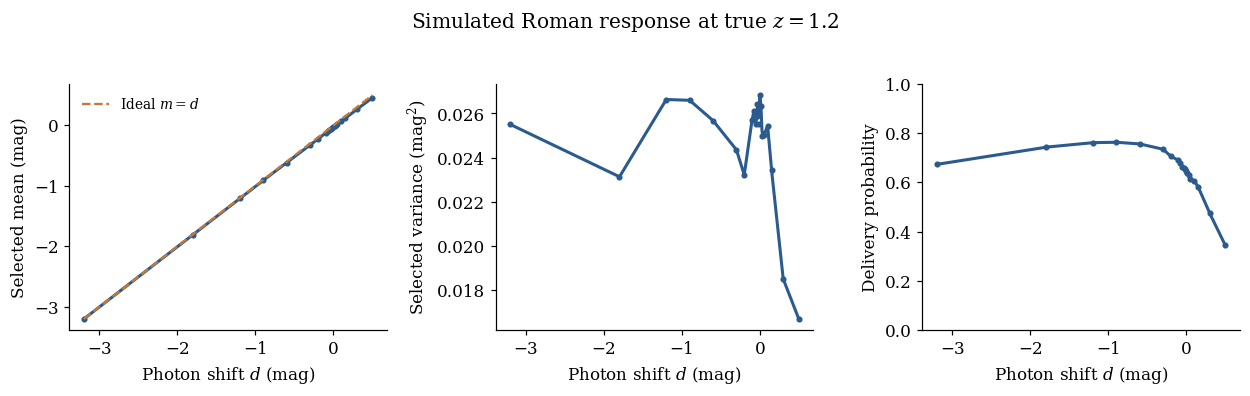

In [4]:
photon_shift = np.linspace(response.shift_nodes[0], response.shift_nodes[-1], 400)
point = response.evaluate(photon_shift, true_redshift, draw=None)
knots = response.evaluate(response.shift_nodes, true_redshift, draw=None)

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5), sharex=True)
fields = ["mean_mag", "variance_mag2", "delivery_probability"]
labels = ["Selected mean (mag)", r"Selected variance (mag$^2$)", "Delivery probability"]
for ax, field, label in zip(axes, fields, labels):
    ax.plot(photon_shift, point[field], color=blue, linewidth=2)
    ax.plot(response.shift_nodes, knots[field], "o", color=blue, markersize=3)
    ax.set(xlabel=r"Photon shift $d$ (mag)", ylabel=label)
axes[0].plot(photon_shift, photon_shift, "--", color=orange, label=r"Ideal $m=d$")
axes[0].legend(fontsize=9)
axes[2].set_ylim(0, 1)
fig.suptitle(r"Simulated Roman response at true $z=1.2$", y=1.02)
fig.tight_layout()
plt.show()

The selected mean roughly tracks the photon shift, but selection and fitting make it differ from the ideal $m=d$ line. The selected variance already includes the SN, fitting and redshift scatter present in this simulation. Adding a generic “15% SN error” would count that scatter again.

Delivery changes across the grid. At a **fixed** magnification, conditioning on a delivered SN cancels $S$ from its brightness density. Delivery remains essential when comparing mixtures of different physical states, as in population inference.

In [5]:
# One saved training event: residual is already in the response's fixed C0 coordinate.
residual_mag = -0.3513132671710686
injected_mu = 10**0.08
injected_shift = magnification_to_shift(injected_mu)
print(f"Training event: y = {residual_mag:.5f} mag; true z = {true_redshift:.1f}")
print(f"Injected magnification = {injected_mu:.4f}; photon shift = {injected_shift:.3f} mag")

Training event: y = -0.35131 mag; true z = 1.2
Injected magnification = 1.2023; photon shift = -0.200 mag


## The conditional brightness likelihood

Each joint calibration draw $\psi$ supplies a selected Gaussian moment density. The public likelihood averages those densities with the saved draw probabilities:

$$L(\mu\mid y,z)=\sum_\psi p(\psi)\,
\mathcal{N}\!\left(y; m_\psi[-2.5\log_{10}\mu,z],
                         v_\psi[-2.5\log_{10}\mu,z]\right).$$

Here redshift is fixed. Attenuation, additional microlensing and post-delivery offsets are zero. There is no lens-mass prior or magnification-density Jacobian. We stay within measured photon-shift support.

We summarize the curve with its peak and the range where $\ln L$ drops by at most 0.5. This is a **likelihood width**, with no asserted interval coverage.

In [6]:
mu_grid = np.linspace(0.67, 2.15, 1601)
log_likelihood = magnification_log_likelihood(
    residual_mag, true_redshift, mu_grid, response,
)
peak_index = int(np.argmax(log_likelihood))
peak_mu = mu_grid[peak_index]
log_drop = log_likelihood.max() - log_likelihood
relative_likelihood = np.exp(-log_drop)
inside = log_drop <= 0.5
# Grid approximation: endpoint precision is about one magnification grid step.
lower_mu, upper_mu = mu_grid[inside][[0, -1]]
fractional_half_width = (upper_mu - lower_mu) / (2 * peak_mu)
assert not inside[0] and not inside[-1], "Extend the grid to bracket the width."
print(f"Likelihood peak: {peak_mu:.4f}")
print(f"Log-drop range: [{lower_mu:.4f}, {upper_mu:.4f}]")
print(f"Fractional half-width: {fractional_half_width:.1%} (grid step {mu_grid[1] - mu_grid[0]:.5f})")

Likelihood peak: 1.3517
Log-drop range: [1.1677, 1.5673]
Fractional half-width: 14.8% (grid step 0.00092)


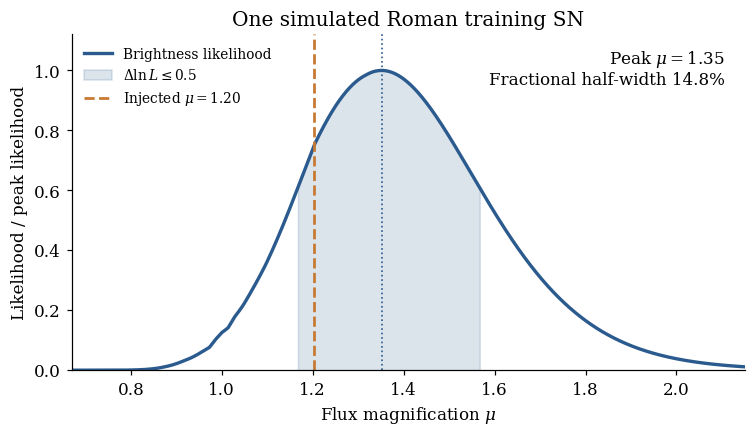

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.1))
ax.plot(mu_grid, relative_likelihood, color=blue, linewidth=2.2,
        label="Brightness likelihood")
ax.fill_between(mu_grid, 0, relative_likelihood, where=inside,
                color=blue, alpha=0.17, label=r"$\Delta\ln L\leq0.5$")
ax.axvline(injected_mu, color=orange, linestyle="--", linewidth=1.8,
           label=rf"Injected $\mu={injected_mu:.2f}$")
ax.axvline(peak_mu, color=blue, linestyle=":", linewidth=1.1)
ax.set(xlabel=r"Flux magnification $\mu$", ylabel="Likelihood / peak likelihood",
       title="One simulated Roman training SN", xlim=(mu_grid[0], mu_grid[-1]), ylim=(0, 1.12))
ax.text(0.97, 0.96, rf"Peak $\mu={peak_mu:.2f}$" + "\n"
        + f"Fractional half-width {fractional_half_width:.1%}",
        transform=ax.transAxes, ha="right", va="top")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

The likelihood peaks near $\mu=1.35$, while the injected magnification is about $1.20$. A noisy residual need not favor the injected value exactly. The approximately **15% fractional half-width** describes this event under this response and these fixed assumptions; it is not a universal per-SN error or a survey precision forecast.

The 2,000 joint draws approximate finite training-sample uncertainty under the supplied simulator and selection. They do not measure real instrument or population-model mismatch. TRAIN20 refined the grid using training parents after earlier validation was opened, with no new independent validation or coverage claim.

## Try a different brightness residual

**Exercise:** before running the next cell, predict how making $y$ more negative changes the preferred magnification. Edit `residual_changes_mag` to compare other residuals while keeping true $z=1.2$ and the same response. If the likelihood peak reaches the grid boundary, its width is not bracketed.

This exercise changes an input residual; it does not generate new Roman light curves or new validation data.

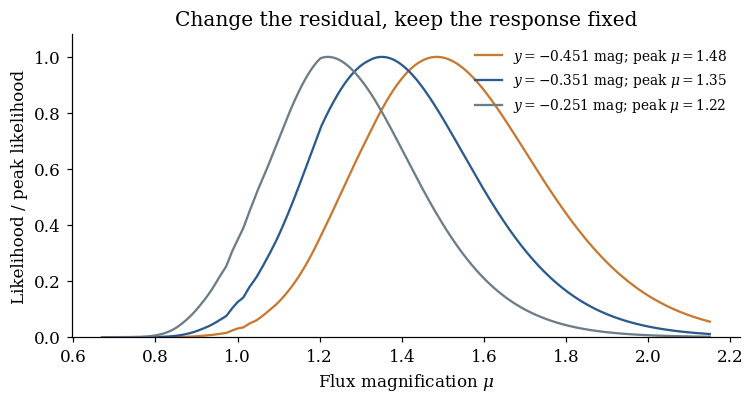

In [8]:
residual_changes_mag = [-0.10, 0.0, 0.10]
colors = [orange, blue, "#6c7d88"]
fig, ax = plt.subplots(figsize=(7, 3.8))
for change_mag, color in zip(residual_changes_mag, colors):
    trial_y = residual_mag + change_mag
    trial_logl = magnification_log_likelihood(trial_y, true_redshift, mu_grid, response)
    trial_peak = mu_grid[np.argmax(trial_logl)]
    ax.plot(mu_grid, np.exp(trial_logl - trial_logl.max()), color=color,
            label=rf"$y={trial_y:.3f}$ mag; peak $\mu={trial_peak:.2f}$")
ax.set(xlabel=r"Flux magnification $\mu$", ylabel="Likelihood / peak likelihood",
       title="Change the residual, keep the response fixed", ylim=(0, 1.08))
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

A more negative residual generally favors larger magnification: the source is brighter relative to the same standardization reference. The response's variance and calibration mixture can also change the likelihood shape, so the shift is not captured by a single constant error bar.

A common mistake is to replace the calibrated mean with $m=d$ and interpret $10^{-0.4y}$ as the final measurement. That conversion is useful intuition; the likelihood accounts for the selected response and its calibration uncertainty.

## Continue exploring

Try a different supported true-redshift center to inspect how the response changes. For the fixed event above, changing its redshift is a sensitivity exercise, not a new observation.

See [the scientific model](../docs/science.rst) for selection in population mixtures, and [the radial-transfer notebook](02_radial_transfer.ipynb) for connecting outer magnification to lens structure. A brightness measurement alone does not determine an inner mass sheet or $H_0$.